# 04 Weather panel

Inspection of the daily weather panel built by `scripts/build_weather_panel.py`:
one row per day and territory, the unweighted mean of the assigned land cells
for each variable, on the published day label `weather_date`.

The first cell checks the panel against the current configuration. It does not
build. A panel built from another cell mask, other variables, another boundaries
layer or another configured span is stale, and the notebook stops there. A panel
covering less than the configured span is incomplete rather than wrong, so the
cell warns and carries on.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from fdh import aggregate
from fdh.config import load_config, repo_root, require
from fdh.grid import LABELS_FILE

config = load_config()
processed = config.paths.resolved("processed_dir")
VARIABLES = require(config.weather.variables, "weather.variables")
COLUMNS = [aggregate.COLUMNS[name] for name in VARIABLES]

record = aggregate.check_current(
    processed / aggregate.RECORD_FILE,
    aggregate.basis(
        config.weather.window_start,
        config.weather.release_covers_to,
        VARIABLES,
        config.boundaries.layer,
        processed / LABELS_FILE,
    ),
)
print(f"The weather panel is current: {record['first_day']} to {record['last_day']}, "
      f"built {record['built_at']}.")

The weather panel is current: 2009-10-01 to 2025-12-31, built 2026-11-22T14:01:11+00:00.


## Load

In [2]:
panel = pd.read_parquet(processed / aggregate.PANEL_FILE)
panel["weather_date"] = pd.to_datetime(panel["weather_date"])
names = pd.read_csv(repo_root() / config.incident_types.crosswalk_file).set_index(
    "e_code_territory"
)["frs_territory"]
panel["territory"] = panel["e_code_territory"].map(names)

print(f"{len(panel):,} rows, {panel.e_code_territory.nunique()} territories, "
      f"{panel.weather_date.min():%Y-%m-%d} to {panel.weather_date.max():%Y-%m-%d}")
print(f"rows with a null variable: {int(panel[COLUMNS].isna().any(axis=1).sum()):,}")

255,248 rows, 43 territories, 2009-10-01 to 2025-12-31
rows with a null variable: 0


## Each territory holds the cells assigned to it

The cell mask reaches the panel through a label array and an index from label
to E code. A shuffled index would give every territory another place's weather
while every guard in the build still passed.

Notebook 01 writes `reports/grid_cells_per_territory.csv` from the per-cell
codes, without going through that index. The count there must equal the count
in the panel on every day, for every territory. Where the counts are distinct
across territories, a shuffled index cannot pass. The cell stops on any
difference.

In [3]:
assigned = pd.read_csv(
    config.paths.resolved("reports_dir") / "grid_cells_per_territory.csv"
).set_index("e_code_territory")["cells"]
compared = panel.groupby("e_code_territory")["cells"].agg(["min", "max"]).join(
    assigned.rename("mask"), how="outer"
)
wrong = compared[(compared["min"] != compared["mask"]) | (compared["max"] != compared["mask"])]
if len(wrong):
    raise ValueError(f"cells per territory in the panel differ from the mask:\n{wrong}")

print(f"{len(compared)} territories hold the cells the mask assigns them on every day; "
      f"counts distinct across territories: {assigned.is_unique}")
print(f"territory-days below the assigned count: {record['territory_days_below_assigned']:,}, "
      f"written as null: {record['null_territory_days']:,}")

43 territories hold the cells the mask assigns them on every day; counts distinct across territories: True
territory-days below the assigned count: 0, written as null: 0


## Three contrasting territories across the span

Cumbria is upland and in the north west, Norfolk is low and in the east, and
Cornwall and Isles of Scilly is maritime and in the south west. Monthly means
are plotted, since sixteen years of daily values do not read at this width.

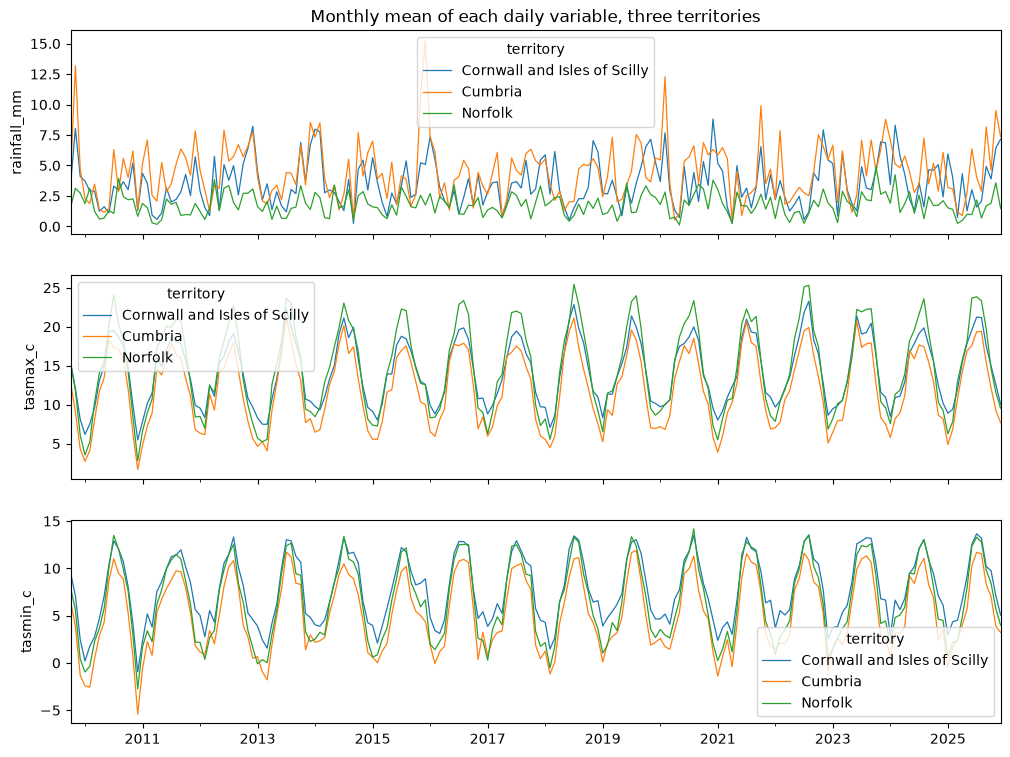

Daily values over the whole span, by territory:
                             rainfall_mm             tasmax_c              tasmin_c              
                                    mean  min    max     mean   min    max     mean    min    max
territory                                                                                        
Cornwall and Isles of Scilly        3.51  0.0  44.75    14.23 -0.01  31.54     7.79  -5.95  17.96
Cumbria                             4.50  0.0  73.28    12.04 -2.91  33.35     5.23 -12.03  17.31
Norfolk                             1.80  0.0  50.94    14.73 -2.60  37.82     6.57 -11.79  19.30


In [4]:
CONTRAST = ["E31000009", "E31000026", "E31000008"]
chosen = panel[panel.e_code_territory.isin(CONTRAST)]
monthly = chosen.groupby(["territory", pd.Grouper(key="weather_date", freq="MS")])[
    COLUMNS
].mean()

fig, axes = plt.subplots(len(COLUMNS), 1, figsize=(12, 9), sharex=True)
for ax, column in zip(axes, COLUMNS, strict=True):
    monthly[column].unstack("territory").plot(ax=ax, linewidth=0.9)
    ax.set_ylabel(column)
    ax.set_xlabel("")
axes[0].set_title("Monthly mean of each daily variable, three territories")
plt.show()

print("Daily values over the whole span, by territory:")
summary = chosen.groupby("territory")[COLUMNS].agg(["mean", "min", "max"])
print(summary.astype(float).round(2).to_string())

## The 2018 and 2022 summers in the rainfall series

Each year is ranked by its rainfall from June to August, summed per territory
and then averaged across territories. The rank is the check: 2018 and 2022
should both sit among the driest summers in the span. If they do not, something
upstream is wrong.

Only years holding all 92 summer days are ranked. A panel that ended part way
through a summer would otherwise rank that year as dry for want of days.

In [5]:
summer = panel[panel.weather_date.dt.month.isin([6, 7, 8])]
year = summer.weather_date.dt.year.rename("year")
complete = summer.groupby(year).weather_date.nunique() == 92
totals = summer.groupby(["e_code_territory", year]).rainfall_mm.sum().groupby("year").mean()
ranking = totals[complete].astype(float).sort_values().round(1)

print(ranking.rename("june_to_august_mm").to_string())
for marked in (2018, 2022):
    print(f"{marked}: rank {ranking.index.get_loc(marked) + 1} of {len(ranking)} from driest")

year
2022    100.6
2018    106.8
2025    129.3
2013    144.2
2024    151.2
2021    177.6
2010    189.0
2016    189.8
2015    194.6
2011    197.2
2014    200.1
2023    232.0
2017    232.7
2019    257.8
2020    259.7
2012    334.0
2018: rank 2 of 16 from driest
2022: rank 1 of 16 from driest


## Neighbouring and distant territories

Pearson correlation of the daily series over the whole span, between Norfolk
and Suffolk and between Cornwall and Isles of Scilly and Northumberland. The
cell counts above show each territory holds the right cells; this shows the
values in them behave like weather.

The judgement rests on rainfall: the neighbouring pair should correlate
strongly and the distant pair weakly. Temperature shares one seasonal cycle
across England, so it correlates highly for any pair and separates the two
only a little.

In [6]:
PAIRS = {
    "neighbouring": ("E31000026", "E31000034"),
    "distant": ("E31000008", "E31000029"),
}
wide = panel.pivot(index="weather_date", columns="e_code_territory", values=COLUMNS)
correlations = pd.DataFrame(
    {
        f"{label}: {names[first]} and {names[second]}": {
            column: wide[column][first].corr(wide[column][second]) for column in COLUMNS
        }
        for label, (first, second) in PAIRS.items()
    }
)
print(correlations.round(3).T.to_string())

                                                          rainfall_mm  tasmax_c  tasmin_c
neighbouring: Norfolk and Suffolk                               0.903     0.995     0.994
distant: Cornwall and Isles of Scilly and Northumberland        0.303     0.915     0.844
